# Weighted PageRank — Part 7
## Which ranking predicts better: the official ranking or weighted PageRank?
**Chakib Madcur · Progress update for the 11/23 meeting**

**The method (Professor Dantsin's description).** I take the two rankings at the end of one season, the official ranking and weighted PageRank, and use each of them to predict the matches of the next season:

- Last season's order, for example **official: A, B, C, D, E** and **PageRank: B, A, C, E, D**.
- In the new season, A and C meet. Both rankings had A above C, so both predict that A wins.
- For each match I write **1** if a ranking predicted the winner correctly and **0** if it did not.
- The **percentage of ones** is that ranking's predictability. If 70 of 100 matches are predicted correctly, it is 70%.
- I do the same for the other ranking and compare the two percentages.

In this part I compare only the official ranking and weighted PageRank.

## Step 1 · Setup
Same data and the same weighted PageRank as in earlier parts (directed graph per season, loser → winner, edge weight = number of wins, *d* = 0.85).

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, binomtest

LOCAL = os.environ.get("LOCAL_DATA")   # optional folder with local copies of the files (faster); otherwise download
def get(url):
    p = os.path.join(LOCAL, url.split("/")[-1]) if LOCAL else None
    return p if p and os.path.exists(p) else url

SACKMANN = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

def load_atp(year):
    m = pd.read_csv(get(SACKMANN + f"atp/atp_matches_{year}.csv"))
    return m[(m.tourney_level != "D") & (~m.tourney_name.isin(["Next Gen Finals", "NextGen Finals", "Laver Cup"]))
             & (~m.score.astype(str).str.contains("W/O", na=False))]
WTA_TOUR = {"G", "W", "I", "P", "PM", "T1", "T2", "T3", "T4", "T5", "O", "F"}
def load_wta(year):
    m = pd.read_csv(get(SACKMANN + f"wta/wta_matches_{year}.csv"))
    return m[m.tourney_level.isin(WTA_TOUR) & (~m.score.astype(str).str.contains("W/O", na=False))]

def weighted_graph(losers, winners, weights=None):
    G = nx.DiGraph()
    for i, (l, w) in enumerate(zip(losers, winners)):
        x = 1.0 if weights is None else weights[i]
        if G.has_edge(l, w):
            G[l][w]["weight"] += x
        else:
            G.add_edge(l, w, weight=x)
    return G

def weighted_pagerank(G, d=0.85, rounds=200):
    players = list(G); n = len(players); idx = {p: i for i, p in enumerate(players)}
    E = list(G.edges(data="weight"))
    L = np.array([idx[u] for u, v, w in E]); W = np.array([idx[v] for u, v, w in E]); x = np.array([w for u, v, w in E], float)
    out = np.bincount(L, weights=x, minlength=n); score = np.full(n, 1 / n)
    for _ in range(rounds):
        unbeaten = score[out == 0].sum()
        score = (1 - d) / n + d * unbeaten / n + np.bincount(W, weights=d * score[L] * x / out[L], minlength=n)
    return pd.Series(score, index=players)

def ranking_files(tour):
    files = ["70s", "80s", "90s", "00s", "10s", "20s"] if tour == "atp" else ["80s", "90s", "00s", "10s", "20s"]
    return pd.concat([pd.read_csv(get(SACKMANN + f"{tour}/{tour}_rankings_{f}.csv")) for f in files])
atp_rankings, wta_rankings = ranking_files("atp"), ranking_files("wta")

def year_end(year, R):
    last = R[R.ranking_date <= year * 10000 + 1231].ranking_date.max()
    return R[R.ranking_date == last].groupby("player")["rank"].min().sort_values()

def predictions(winners, losers, official_above, pagerank):
    """1 if the ranking had the winner above the loser, 0 if below, 0.5 if tied (no prediction)."""
    o = np.array([official_above(a, b) for a, b in zip(winners, losers)], float)
    p = np.array([np.sign(pagerank[a] - pagerank[b]) for a, b in zip(winners, losers)], float)
    return np.where(o == 0, 0.5, (o > 0) * 1.0), np.where(p == 0, 0.5, (p > 0) * 1.0)

def tennis_predict(loader, R, season):
    """Rankings at the end of season-1 predict the matches of season (both players ranked by both)."""
    prev = loader(season - 1)
    pr = weighted_pagerank(weighted_graph(prev.loser_id, prev.winner_id))
    official = year_end(season - 1, R); official = official[official.index.isin(pr.index)]
    m = loader(season); m = m[m.winner_id.isin(official.index) & m.loser_id.isin(official.index)]
    o, p = predictions(m.winner_id, m.loser_id, lambda a, b: np.sign(official[b] - official[a]), pr)
    return m, o, p, official, pr

def summary(o, p):
    dis = (o != p) & (o != 0.5) & (p != 0.5)
    return {"Matches": len(o), "Official correct": int(o.sum()), "Official %": 100 * o.mean(),
            "PageRank correct": int(p.sum()), "PageRank %": 100 * p.mean(),
            "Rankings disagree": int(dis.sum()), "PageRank right when they disagree (%)": 100 * p[dis].mean() if dis.any() else np.nan}

## Step 2 · Worked example: 2024 rankings predict 2025, and 2025 rankings predict 2026 (January–May)
Every tour-level match of the new season between two players who were ranked by both rankings at the end of the previous season.

In [2]:
names = {}
rows = {}
for tour, loader, R in [("Men (ATP)", load_atp, atp_rankings), ("Women (WTA)", load_wta, wta_rankings)]:
    for season in [2025, 2026]:
        m, o, p, official, pr = tennis_predict(loader, R, season)
        names.update(dict(zip(m.winner_id, m.winner_name)) | dict(zip(m.loser_id, m.loser_name)))
        label = f"{tour}: {season - 1} rankings → {season} matches" + (" (Jan–May)" if season == 2026 else "")
        rows[label] = summary(o, p)
example = pd.DataFrame(rows).T
example.style.format({"Matches": "{:,.0f}", "Official correct": "{:,.0f}", "PageRank correct": "{:,.0f}", "Rankings disagree": "{:,.0f}",
                      "Official %": "{:.1f}", "PageRank %": "{:.1f}", "PageRank right when they disagree (%)": "{:.1f}"})

,Matches,Official correct,Official %,PageRank correct,PageRank %,Rankings disagree,PageRank right when they disagree (%)
Men (ATP): 2024 rankings → 2025 matches,"2,391","1,500",62.7,"1,492",62.4,193,47.7
Men (ATP): 2025 rankings → 2026 matches (Jan–May),"1,202",766,63.7,762,63.4,102,48.0
Women (WTA): 2024 rankings → 2025 matches,"2,199","1,355",61.6,"1,348",61.3,231,48.5
Women (WTA): 2025 rankings → 2026 matches (Jan–May),"1,132",706,62.4,716,63.3,128,53.9


One match where the two rankings disagreed, to show the counting (2026, men):

In [3]:
m, o, p, official, pr = tennis_predict(load_atp, atp_rankings, 2026)
pr_rank = (-pr).rank(method="min").astype(int)
dis = np.where((o != p) & (o != 0.5) & (p != 0.5))[0]
for i in dis[:3]:
    r = m.iloc[i]
    print(f"{r.tourney_name} 2026: {r.winner_name} beat {r.loser_name}")
    print(f"   2025 official ranks: {r.winner_name} #{official[r.winner_id]}, {r.loser_name} #{official[r.loser_id]} -> official predicted "
          f"{r.winner_name if official[r.winner_id] < official[r.loser_id] else r.loser_name}: {int(o[i])}")
    print(f"   2025 PageRank ranks: {r.winner_name} #{pr_rank[r.winner_id]}, {r.loser_name} #{pr_rank[r.loser_id]} -> PageRank predicted "
          f"{r.winner_name if pr[r.winner_id] > pr[r.loser_id] else r.loser_name}: {int(p[i])}")

United Cup 2026: Jakub Mensik beat Casper Ruud
   2025 official ranks: Jakub Mensik #19, Casper Ruud #12 -> official predicted Casper Ruud: 0
   2025 PageRank ranks: Jakub Mensik #18, Casper Ruud #19 -> PageRank predicted Jakub Mensik: 1
United Cup 2026: Billy Harris beat Shintaro Mochizuki
   2025 official ranks: Billy Harris #128, Shintaro Mochizuki #99 -> official predicted Shintaro Mochizuki: 0
   2025 PageRank ranks: Billy Harris #141, Shintaro Mochizuki #146 -> PageRank predicted Billy Harris: 1
Brisbane 2026: Sebastian Korda beat Valentin Vacherot
   2025 official ranks: Sebastian Korda #48, Valentin Vacherot #31 -> official predicted Valentin Vacherot: 0
   2025 PageRank ranks: Sebastian Korda #51, Valentin Vacherot #52 -> PageRank predicted Sebastian Korda: 1


**What this says:** in both examples the two percentages are within one point of each other. In 2025 the official ranking was slightly better for both men and women. In the first months of 2026 the official ranking was slightly better for men and PageRank was better for women. The two rankings make the same prediction for about nine matches in ten, so the comparison is really decided by the few matches where they disagree.

## Step 3 · Every season
Men: 1973 rankings predict 1974, and so on, up to 2024 → 2025 (52 seasons). Women: 1984 → 1985 up to 2024 → 2025 (41 seasons).

In [4]:
def all_seasons(loader, R, first, last):
    rows = []
    for season in range(first, last + 1):
        m, o, p, official, pr = tennis_predict(loader, R, season)
        rows.append({"Season": season} | summary(o, p))
    return pd.DataFrame(rows).set_index("Season")

def pval(p):
    return "< 0.01" if p < 0.01 else f"= {p:.2f}"

def report(h, label):
    pooled_o = (h["Official correct"].sum()) / h.Matches.sum() * 100; pooled_p = h["PageRank correct"].sum() / h.Matches.sum() * 100
    right = (h["Rankings disagree"] * h["PageRank right when they disagree (%)"] / 100).sum(); dis = h["Rankings disagree"].sum()
    print(f"{label}: {len(h)} seasons, {h.Matches.sum():,} matches")
    print(f"  % correct, all matches together: official {pooled_o:.1f}%, PageRank {pooled_p:.1f}%")
    print(f"  Seasons where PageRank predicted better: {(h['PageRank %'] > h['Official %']).sum()}, official better: {(h['Official %'] > h['PageRank %']).sum()} "
          f"(paired test p {pval(wilcoxon(h['PageRank %'], h['Official %']).pvalue)})")
    print(f"  The rankings disagree on {dis:,} matches ({dis / h.Matches.sum():.0%}); PageRank was right in {right / dis:.1%} of them (p {pval(binomtest(int(round(right)), int(dis)).pvalue)})")

atp = all_seasons(load_atp, atp_rankings, 1974, 2025); wta = all_seasons(load_wta, wta_rankings, 1985, 2025)
report(atp, "Men (ATP)"); report(wta, "Women (WTA)")
for a, b in [(1974, 1990), (1991, 2025)]:
    x = atp.loc[a:b]
    print(f"Men {a}–{b}: official {x['Official %'].mean():.1f}%, PageRank {x['PageRank %'].mean():.1f}%; PageRank better in {(x['PageRank %'] > x['Official %']).sum()} of {len(x)} seasons "
          f"(p {pval(wilcoxon(x['PageRank %'], x['Official %']).pvalue)})")

Men (ATP): 52 seasons, 135,554 matches
  % correct, all matches together: official 64.4%, PageRank 64.5%
  Seasons where PageRank predicted better: 25, official better: 27 (paired test p = 0.66)
  The rankings disagree on 14,153 matches (10%); PageRank was right in 50.5% of them (p = 0.26)
Women (WTA): 41 seasons, 86,244 matches
  % correct, all matches together: official 65.0%, PageRank 64.5%
  Seasons where PageRank predicted better: 8, official better: 33 (paired test p < 0.01)
  The rankings disagree on 8,050 matches (9%); PageRank was right in 47.7% of them (p < 0.01)
Men 1974–1990: official 66.9%, PageRank 66.5%; PageRank better in 4 of 17 seasons (p = 0.03)
Men 1991–2025: official 63.1%, PageRank 63.5%; PageRank better in 21 of 35 seasons (p = 0.04)


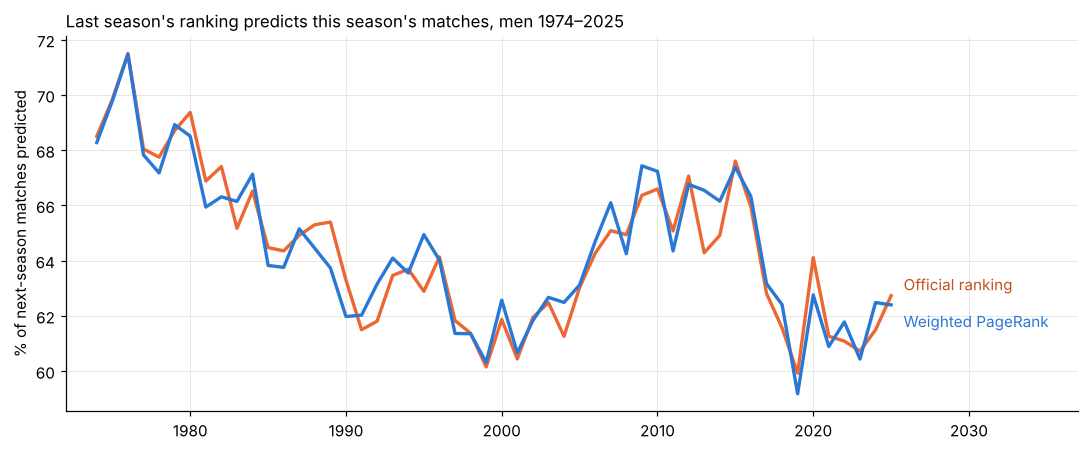

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(atp.index, atp["Official %"], color=ORANGE, lw=2.2)
ax.plot(atp.index, atp["PageRank %"], color=BLUE, lw=2.2)
ax.text(2025.8, atp.loc[2025, "Official %"] + 0.4, "Official ranking", color="#c4521f", fontsize=10, va="center")
ax.text(2025.8, atp.loc[2025, "PageRank %"] - 0.6, "Weighted PageRank", color=BLUE, fontsize=10, va="center")
ax.set_xlim(1972, 2037); ax.set_ylabel("% of next-season matches predicted")
ax.set_title("Last season's ranking predicts this season's matches, men 1974–2025", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig("prediction_by_season.png", dpi=200); plt.show()

**What this says**
- **Men:** over 52 seasons the two rankings predict equally well (about 64% each). Before 1990, when the ATP ranking was an average of points per tournament, the official ranking was usually better; since 1991 PageRank has been better in 21 of 35 seasons, by a small margin (63.5% against 63.1%). When the two rankings disagree, PageRank is right about half the time.
- **Women:** the official WTA ranking predicts slightly but consistently better (65.0% against 64.5%, better in 33 of 41 seasons).

## Step 4 · What is the best way to measure predictability?
| Measure | What it answers | Strength | Weakness |
|---|---|---|---|
| **% of matches predicted correctly** (the method above) | How often is the ranking right? | Simple and easy to explain | The two rankings agree on about 90% of matches, so the two percentages are always close |
| **% correct only where the rankings disagree** | When they predict different winners, which one is right? | Isolates the real difference between the rankings | Uses fewer matches |
| **Seasons won, with a paired test** | Is a difference consistent over time, or luck? | Shows whether a result holds season after season | Needs many seasons |
| Probability scores (Brier score, log loss) | How good are the predicted probabilities? | Standard for forecasts | A ranking gives an order, not probabilities, so it does not apply here |

**What I use:** the percentage of matches predicted correctly as the main measure (the professor's method), the matches where the two rankings disagree as the deciding check, and the season-by-season count with a paired test to see whether a difference is real.

In [6]:
share = pd.DataFrame({"Matches": [atp.Matches.sum(), wta.Matches.sum()],
                      "Both rankings make the same prediction (%)": [100 - 100 * atp["Rankings disagree"].sum() / atp.Matches.sum(), 100 - 100 * wta["Rankings disagree"].sum() / wta.Matches.sum()]},
                     index=["Men 1974–2025", "Women 1985–2025"])
share.round(1)

,Matches,Both rankings make the same prediction (%)
Men 1974–2025,135554,89.6
Women 1985–2025,86244,90.7


## Step 5 · Other sports
The same test: last season's official standings and last season's weighted PageRank predict the next season's games. Draws are left out (neither team won), and in the Premier League the three promoted teams are left out (they had no Premier League ranking the season before). For international football, the official ranking is the FIFA ranking of 18 July 2024 and PageRank uses the matches from August 2018 to July 2024; they predict every match between FIFA members after that date.

In [7]:
NHL_2024_25_POINTS = {"TOR": 108, "TBL": 102, "FLA": 98, "OTT": 97, "MTL": 91, "DET": 86, "BUF": 79, "BOS": 76, "WSH": 111, "CAR": 99, "NJD": 91,
    "CBJ": 89, "NYR": 85, "NYI": 82, "PIT": 80, "PHI": 76, "WPG": 116, "DAL": 106, "COL": 102, "MIN": 97, "STL": 96, "UTA": 89, "NSH": 68, "CHI": 61,
    "VGK": 110, "LAK": 105, "EDM": 101, "CGY": 96, "VAN": 90, "ANA": 80, "SEA": 76, "SJS": 52}   # official 2024-25 standings points

def game_edges(h, a, hs, as_):
    L, W, X = [], [], []
    for x, y, p, q in zip(h, a, hs, as_):
        if p > q: L.append(y); W.append(x); X.append(1.0)
        elif p < q: L.append(x); W.append(y); X.append(1.0)
        else: L += [x, y]; W += [y, x]; X += [0.5, 0.5]      # draw: half a win each way
    return L, W, X

def decided(h, a, hs, as_):
    keep = hs != as_
    return np.where(hs > as_, h, a)[keep], np.where(hs > as_, a, h)[keep]

def league(name, season):
    if name == "NFL":
        d = pd.read_csv(get("https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv"), low_memory=False)
        d = d[(d.season == season) & (d.game_type == "REG")].dropna(subset=["home_score"])
        return d.home_team.values, d.away_team.values, d.home_score.values, d.away_score.values
    if name == "NBA":
        d = pd.read_parquet(get(f"https://raw.githubusercontent.com/sportsdataverse/hoopR-nba-data/main/nba/schedules/parquet/nba_schedule_{season}.parquet"))
        d = d[(d.season_type == 2) & (d.type_abbreviation == "STD") & (d.status_type_completed == True)]
        d = d[~d.notes_headline.fillna("").str.contains("All-Star|Cup Championship")]
        return d.home_display_name.values, d.away_display_name.values, d.home_score.astype(float).values, d.away_score.astype(float).values
    if name == "NHL":
        d = pd.read_parquet(get(f"https://raw.githubusercontent.com/sportsdataverse/fastRhockey-nhl-data/main/nhl/schedules/parquet/nhl_schedule_{season}.parquet"))
        d = d[d.game_type == "R"]
        return d.home_team_abbr.values, d.away_team_abbr.values, d.home_score.values, d.away_score.values
    d = pd.read_csv(get(f"https://raw.githubusercontent.com/datasets/football-datasets/main/datasets/premier-league/season-{season}.csv"))
    return d.HomeTeam.values, d.AwayTeam.values, d.FTHG.values, d.FTAG.values

def standings(h, a, hs, as_, points_per_win):
    t = pd.DataFrame({"team": list(h) + list(a), "f": list(hs) + list(as_), "g": list(as_) + list(hs)})
    T = t.assign(W=t.f > t.g, D=t.f == t.g).groupby("team").agg(G=("f", "size"), W=("W", "sum"), D=("D", "sum"))
    return points_per_win * T.W + T.D if points_per_win == 3 else (T.W + 0.5 * T.D) / T.G

def predict_league(name, prev, nxt):
    h, a, hs, as_ = league(name, prev)
    L, W, X = game_edges(h, a, hs, as_)
    pr = weighted_pagerank(weighted_graph(L, W, X))
    official = (pd.Series(NHL_2024_25_POINTS, dtype=float) if name == "NHL"
                else standings(h, a, hs, as_, 3 if name == "Premier League" else 1))
    win, lose = decided(*league(name, nxt))
    keep = np.array([x in official.index and y in official.index and x in pr.index and y in pr.index for x, y in zip(win, lose)])
    return predictions(win[keep], lose[keep], lambda x, y: np.sign(official[x] - official[y]), pr)

FIFA_NAMES = {"USA": "United States", "Turkiye": "Turkey", "Czechia": "Czech Republic", "Congo DR": "DR Congo", "Bosnia & Herzegovina": "Bosnia and Herzegovina",
    "Curacao": "Curaçao", "Trinidad & Tobago": "Trinidad and Tobago", "Kyrgyz Republic": "Kyrgyzstan", "Korea DPR": "North Korea", "St Kitts and Nevis": "Saint Kitts and Nevis",
    "Chinese Taipei": "Taiwan", "Papa New Guinea": "Papua New Guinea", "St Lucia": "Saint Lucia", "St Vincent and the Grenadines": "Saint Vincent and the Grenadines",
    "Brunei Darussalam": "Brunei", "Sao Tome and Principe": "São Tomé and Príncipe", "US Virgin Islands": "United States Virgin Islands"}
def predict_international():
    fifa = pd.read_csv(get("https://raw.githubusercontent.com/ChakibMadcur/tennis-pagerank-research/main/data/fifa_ranking_2024_07_18.csv"))
    official = fifa.assign(team=fifa.team.replace(FIFA_NAMES)).set_index("team")["rank"]
    r = pd.read_csv(get("https://raw.githubusercontent.com/martj42/international_results/master/results.csv")).dropna(subset=["home_score"])
    r["date"] = pd.to_datetime(r.date); r = r[r.home_team.isin(official.index) & r.away_team.isin(official.index)]
    past = r[(r.date >= "2018-08-16") & (r.date <= "2024-07-18")]; future = r[r.date > "2024-07-18"]
    L, W, X = game_edges(past.home_team, past.away_team, past.home_score, past.away_score)
    pr = weighted_pagerank(weighted_graph(L, W, X))
    win, lose = decided(future.home_team.values, future.away_team.values, future.home_score.values, future.away_score.values)
    keep = np.array([x in pr.index and y in pr.index for x, y in zip(win, lose)])
    return predictions(win[keep], lose[keep], lambda x, y: np.sign(official[y] - official[x]), pr), future.date.max()

sports = {}
for name, prev, nxt, label in [("NFL", 2024, 2025, "NFL: 2024 → 2025"), ("NBA", 2025, 2026, "NBA: 2024–25 → 2025–26"),
                               ("NHL", 2025, 2026, "NHL: 2024–25 → 2025–26"), ("Premier League", "2425", "2526", "Premier League: 2024–25 → 2025–26")]:
    sports[label] = summary(*predict_league(name, prev, nxt))
(o, p), last = predict_international()
sports[f"International football: FIFA ranking of July 2024 → matches to {last:%b %Y}"] = summary(o, p)
for k, (tour, loader, R) in {"Men's tennis: 2024 → 2025": ("atp", load_atp, atp_rankings), "Women's tennis: 2024 → 2025": ("wta", load_wta, wta_rankings)}.items():
    _, o, p, _, _ = tennis_predict(loader, R, 2025); sports[k] = summary(o, p)
T = pd.DataFrame(sports).T
T["p (disagreements)"] = [binomtest(int(round(r["Rankings disagree"] * r["PageRank right when they disagree (%)"] / 100)), int(r["Rankings disagree"])).pvalue for _, r in T.iterrows()]
T.style.format({"Matches": "{:,.0f}", "Official correct": "{:,.0f}", "PageRank correct": "{:,.0f}", "Rankings disagree": "{:,.0f}",
                "Official %": "{:.1f}", "PageRank %": "{:.1f}", "PageRank right when they disagree (%)": "{:.1f}", "p (disagreements)": "{:.2f}"})

,Matches,Official correct,Official %,PageRank correct,PageRank %,Rankings disagree,PageRank right when they disagree (%),p (disagreements)
NFL: 2024 → 2025,271,154,56.8,158,58.3,37,54.1,0.74
NBA: 2024–25 → 2025–26,"1,230",726,59.0,704,57.2,105,38.1,0.02
NHL: 2024–25 → 2025–26,"1,312",667,50.9,661,50.4,70,45.7,0.55
Premier League: 2024–25 → 2025–26,203,118,58.4,121,59.6,20,55.0,0.82
International football: FIFA ranking of July 2024 → matches to Nov 2026,"1,909","1,462",76.6,"1,438",75.3,200,44.0,0.10
Men's tennis: 2024 → 2025,"2,391","1,500",62.7,"1,492",62.4,193,47.7,0.56
Women's tennis: 2024 → 2025,"2,199","1,355",61.6,"1,348",61.3,231,48.5,0.69


**What this says:** the result depends on the sport, and none of the differences is large. Weighted PageRank predicted the next season slightly better in the NFL and the Premier League; the official ranking predicted slightly better in the NBA, the NHL and international football. Hockey is close to a coin flip from one season to the next for both rankings. Several of these samples are small (one season of games), so they are first results, not conclusions.

## Findings
1. **Method:** each ranking at the end of a season predicts the winners of the next season's matches; the percentage of correct predictions measures its predictability.
2. **Tennis:** for men, the official ranking and weighted PageRank predict equally well over five decades (about 64%); the official ranking was better before 1990, and since 1991 weighted PageRank has been slightly better (21 of 35 seasons). For women, the WTA ranking predicts slightly better (65.0% against 64.5%).
3. **Worked example:** 2024 rankings predicting 2025 matches — official 62.7%, PageRank 62.4% (men); the two rankings make the same prediction for about nine matches in ten.
4. **Best way to measure:** the percentage correct as the main number, plus the matches where the rankings disagree as the deciding check, plus a season-by-season paired test.
5. **Other sports:** mixed and close — PageRank slightly better in the NFL and the Premier League, the official ranking slightly better in the NBA, the NHL and international football.